## 1) Image Negative

\[
s = 255 - r
\]

255 0


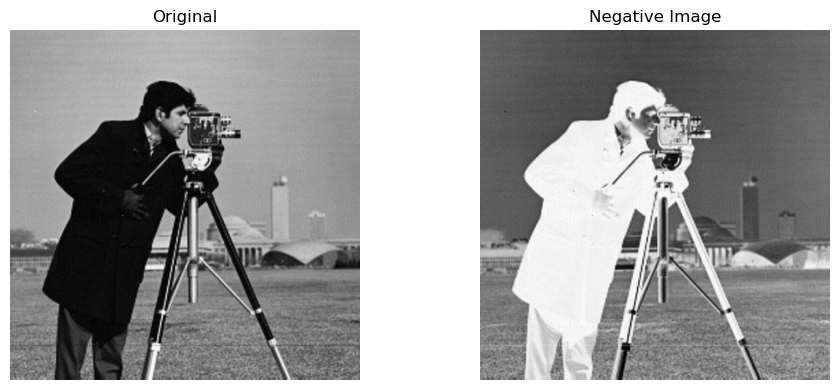

In [11]:
import matplotlib.pyplot as plt
import numpy as np

img_input = plt.imread("Used_Images/negative.jpg")
print(img_input.max(), img_input.min())
out_img = 255 - img_input

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(img_input, cmap='gray')
ax[0].set_title("Original")
ax[0].axis('off')

ax[1].imshow(out_img, cmap='gray')
ax[1].set_title("Negative Image")
ax[1].axis('off')

plt.tight_layout()
plt.show()


## 2) Contrast Stretch

uint8
90 140
0.18685322 0.62015265


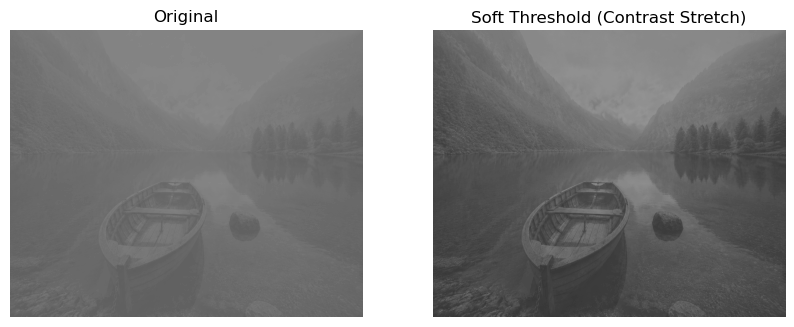

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_input1 = cv2.imread("Used_Images/contrast.png", cv2.IMREAD_GRAYSCALE)

print(img_input1.dtype)
print(img_input1.min(), img_input1.max())

img = img_input1.astype(np.float32) / 255

k = 10
r0 = 0.5

out_contrast = 1 / (1 + np.exp(-k*(img-r0)))

print(out_contrast.min(), out_contrast.max())

fig, ax = plt.subplots(1,2, figsize=(10,4))

ax[0].imshow(img, cmap='gray', vmin=0, vmax=1)
ax[0].set_title("Original")
ax[0].axis('off')

ax[1].imshow(out_contrast, cmap='gray', vmin=0, vmax=1)
ax[1].set_title("Soft Threshold (Contrast Stretch)")
ax[1].axis('off')

plt.show()




## 3) Threshold Function


255 0


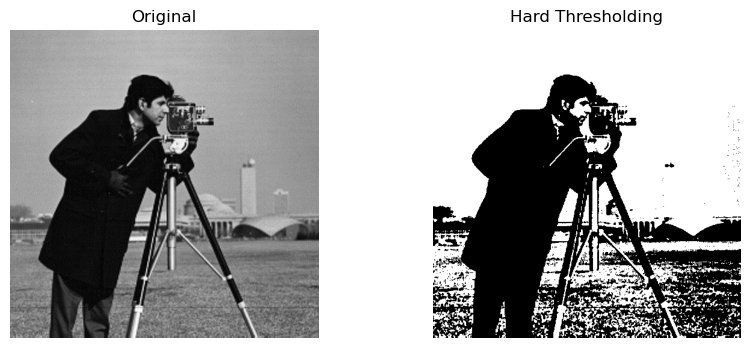

In [19]:
import numpy as np
import matplotlib.pyplot as plt

img_input2 = plt.imread("Used_Images/negative.jpg")
print(img_input2.max(), (img_input2.min()))
T = 128
out_threshold = np.where(img_input2 >= T, 255, 0)

fig, ax = plt.subplots(1,2, figsize=(10,4))

ax[0].imshow(img_input2, cmap='gray', vmin=0, vmax=1)
ax[0].set_title("Original")
ax[0].axis('off')

ax[1].imshow(out_threshold, cmap='gray', vmin=0, vmax=1)
ax[1].set_title("Hard Thresholding")
ax[1].axis('off')

plt.show()



## 4) Log Transform

\[
s = c log(1+r)
\]

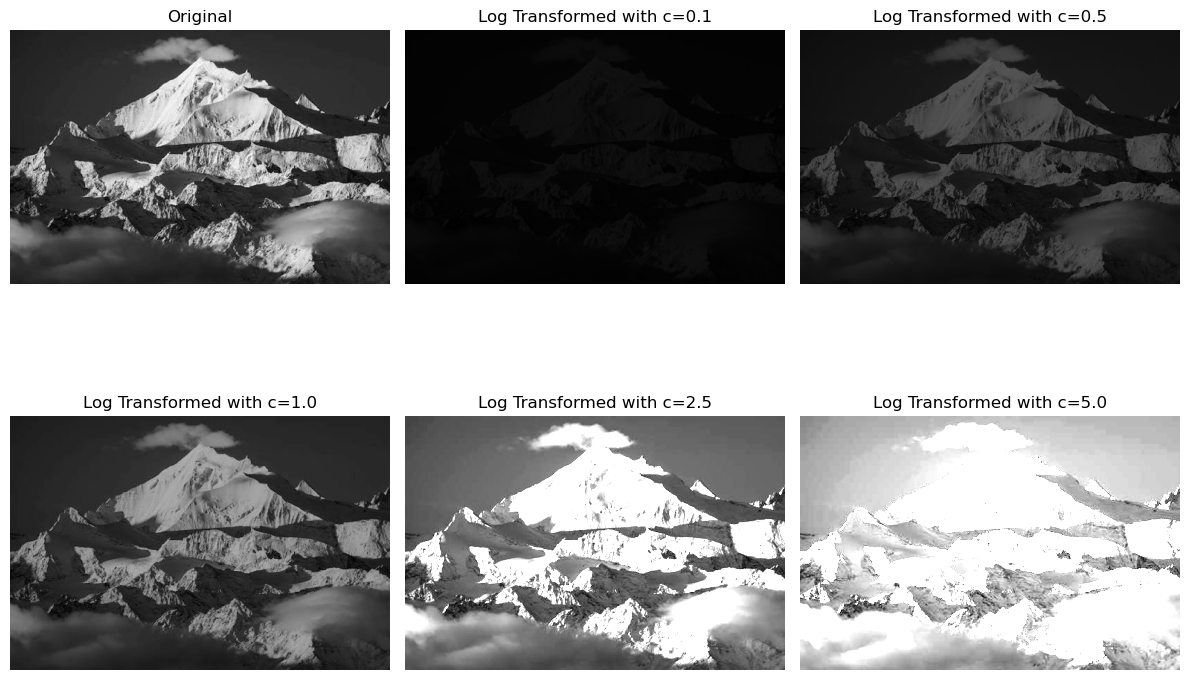

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img1 = cv2.imread("Used_Images/img.jpg", cv2.IMREAD_GRAYSCALE)
img1 = img1.astype(float) / 255 

C = [0.1, 0.5, 1.0, 2.5, 5.0]

fig, ax = plt.subplots(2,3, figsize=(12,9))
ax = ax.ravel()
ax[0].imshow(img1, cmap='gray', vmin=0, vmax=1)
ax[0].set_title("Original")
ax[0].axis('off')

for i, c in enumerate(C):
    out_log = c * np.log(1 + img1)
    ax[i+1].imshow(out_log, cmap='gray', vmin=0, vmax=1)
    ax[i+1].set_title(f"Log Transformed with c={c}")
    ax[i+1].axis('off')
    
plt.tight_layout()
plt.show()


## 5) Inverse Log Transform


246 0


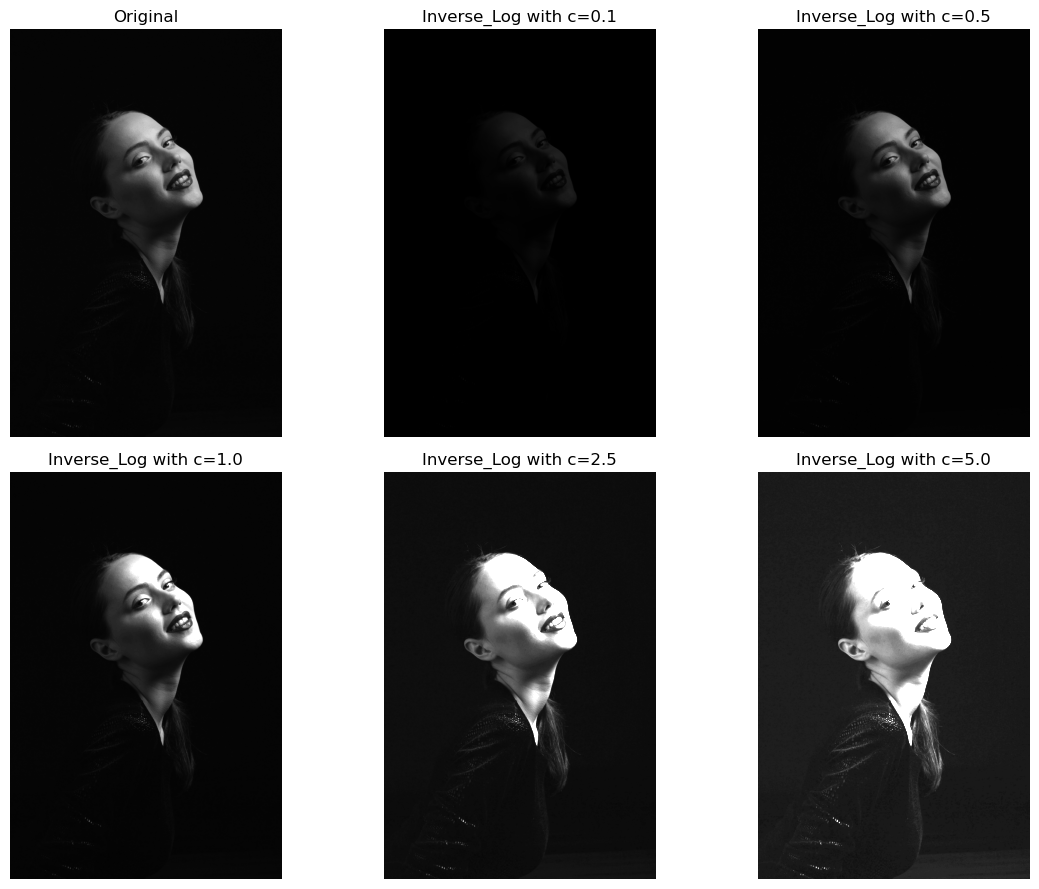

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img2 = cv2.imread("Used_Images/inv.jpg", cv2.IMREAD_GRAYSCALE)
print(img2.max(), img2.min())

img2 = img2.astype(float)
img2 = img2 / 255
costant = [0.1, 0.5, 1.0, 2.5, 5.0]

fig, ax = plt.subplots(2,3, figsize=(12,9))
ax = ax.ravel()
ax[0].imshow(img2, cmap='gray', vmin=0, vmax=1)
ax[0].set_title("Original")
ax[0].axis('off')
for i, c in enumerate(costant):
    out_inv_log = c * (np.exp(img2) - 1)
    
    ax[i+1].imshow(out_inv_log, cmap='gray', vmin=0, vmax=1)
    ax[i+1].set_title(f"Inverse_Log with c={c}")
    ax[i+1].axis('off')
    
plt.tight_layout()
plt.show()

## 6) Power Law / Gamma Transform


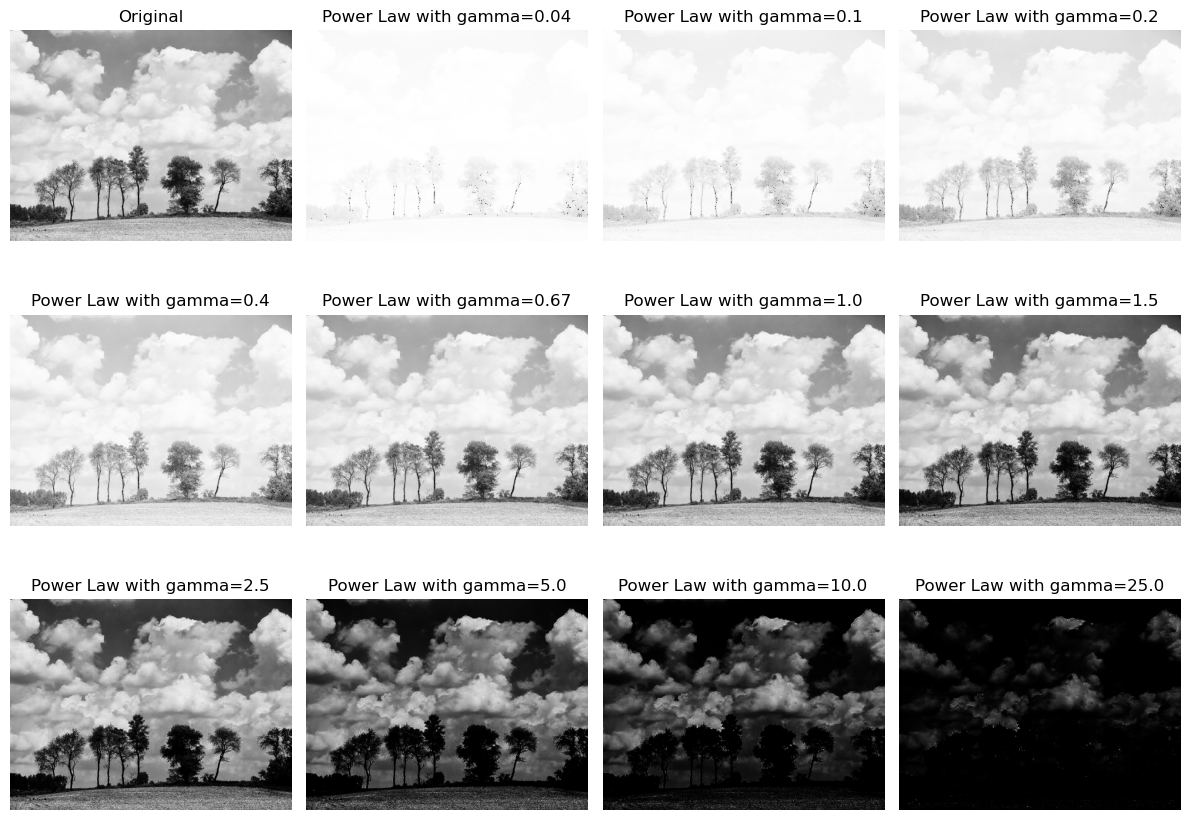

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img3 = cv2.imread("Used_Images/gamma.jpg", cv2.IMREAD_GRAYSCALE)
img3 = img3.astype(float) / 255
c = 1
gamma = [0.04, 0.1, 0.2, 0.4, 0.67,
         1.0, 1.5, 2.5, 5.0, 10.0, 25.0]


fig, ax = plt.subplots(3, 4, figsize=(12,9))
ax = ax.ravel()
ax[0].imshow(img3, cmap='gray', vmin=0, vmax=1)
ax[0].set_title("Original")
ax[0].axis('off')

for i, g in enumerate(gamma):
    power_img = c * (img3 ** g)
    
    ax[i+1].imshow(power_img, cmap='gray', vmin=0, vmax=1)
    ax[i+1].set_title(f"Power Law with gamma={g}")
    ax[i+1].axis('off')

plt.tight_layout()
plt.show()

## 7) Piecewise Transformations

1. **Piecewise Linear**
2. **Intensity_Level Slicing (without Background)**
3. **Intensity_Level Slicing (with Background)**
4. **Bit Plane Slicing**


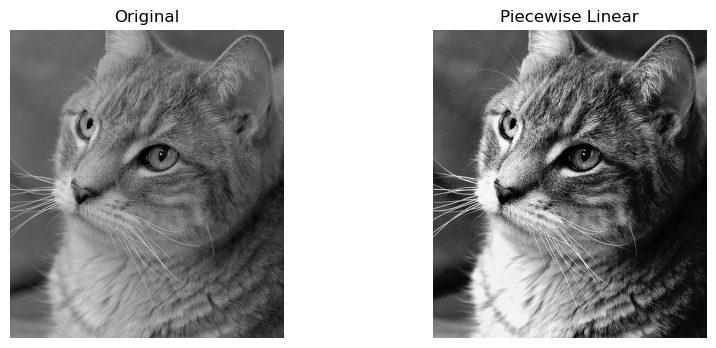

In [28]:
# 1- Piecewise Linear

import cv2
import numpy as np
import matplotlib.pyplot as plt

img4 = cv2.imread("Used_Images/low3.jpg", cv2.IMREAD_GRAYSCALE)

# Transform Point
r1, s1 = 70, 20
r2, s2 = 180, 240

out = np.zeros_like(img4)


for i in range(img4.shape[0]):
    for j in range(img4.shape[1]):

        r = img4[i, j]

        if r <= r1:
            out[i, j] = (s1 / r1) * r

        elif r <= r2:
            out[i, j] = ((s2 - s1) / (r2 - r1)) * (r - r1) + s1

        else:
            out[i, j] = ((255 - s2) / (255 - r2)) * (r - r2) + s2


fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(img4, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Original")
ax[0].axis("off")

ax[1].imshow(out, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Piecewise Linear")
ax[1].axis("off")

plt.show()

(-0.5, 647.5, 472.5, -0.5)

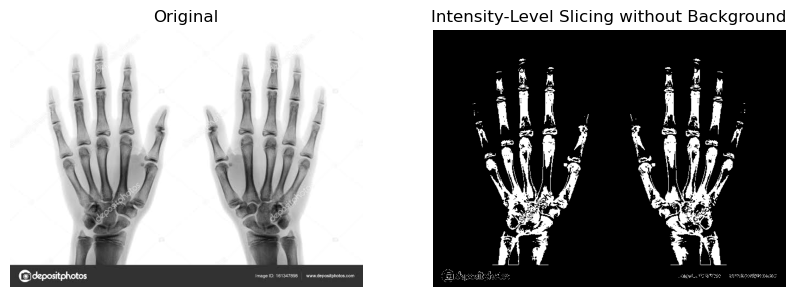

In [3]:
# 2- Intensity_Level slicing (Without Background)

import cv2
import numpy as np
import matplotlib.pyplot as plt

img5 = cv2.imread("Used_Images/hand.jpg", cv2.IMREAD_GRAYSCALE)

A = 80
B = 150

out1 = np.zeros_like(img5)

for i in range(img5.shape[0]):
    for j in range(img5.shape[1]):

        if A <= img5[i, j] <= B:
            out1[i, j] = 255
        else:
            out1[i, j] = 0


fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(img5, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Original")
ax[0].axis("off")

ax[1].imshow(out1, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Intensity-Level Slicing without Background")
ax[1].axis("off")


(-0.5, 647.5, 472.5, -0.5)

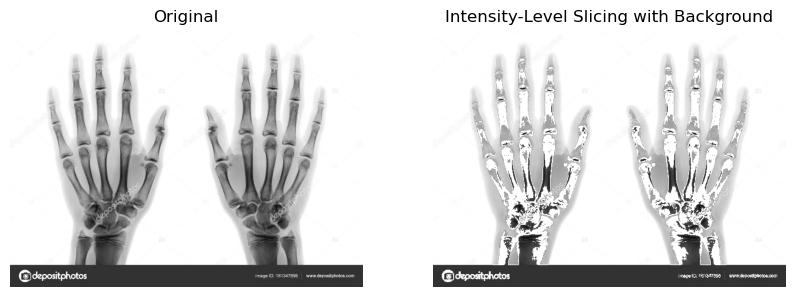

In [30]:
# 3- Intensity_Level slicing (With Background)

import cv2
import numpy as np
import matplotlib.pyplot as plt

img0 = cv2.imread("Used_Images/hand.jpg", cv2.IMREAD_GRAYSCALE)

A = 80
B = 150

out0 = img0.copy()

for i in range(img0.shape[0]):
    for j in range(img0.shape[1]):

        if A <= img0[i, j] <= B:
            out0[i, j] = 255
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(img0, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Original")
ax[0].axis("off")

ax[1].imshow(out0, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Intensity-Level Slicing with Background")
ax[1].axis("off")


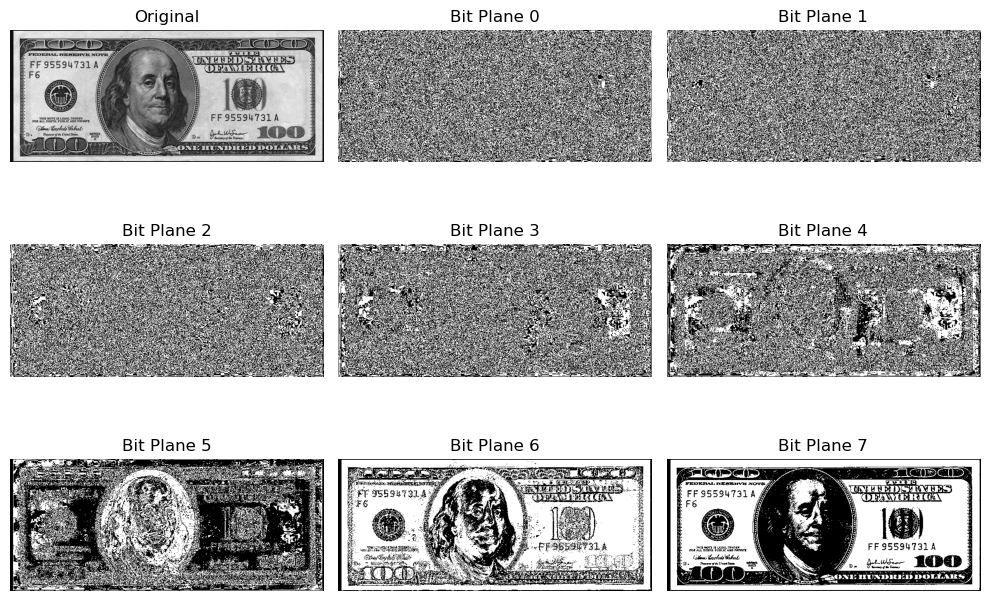

In [32]:
# 4- Bit Plane Slicing

import cv2
import matplotlib.pyplot as plt

img6 = cv2.imread("Used_Images/cash3.jpg", cv2.IMREAD_GRAYSCALE)

fig, ax = plt.subplots(3, 3, figsize=(10, 7))

ax = ax.ravel()

ax[0].imshow(img6, cmap='gray', vmin=0, vmax=255)
ax[0].set_title("Original")
ax[0].axis("off")

for k in range(8):

    bit_plane = ((img6 >> k) & 1) * 255

    ax[k+1].imshow(bit_plane, cmap='gray', vmin=0, vmax=255)
    ax[k+1].set_title(f"Bit Plane {k}")
    ax[k+1].axis("off")

plt.tight_layout()
plt.show()

## 8) Histogram Processing

1. **Histogram Equalization**
2. **Histogram Matching**
3. **Local Histogram Statistics**



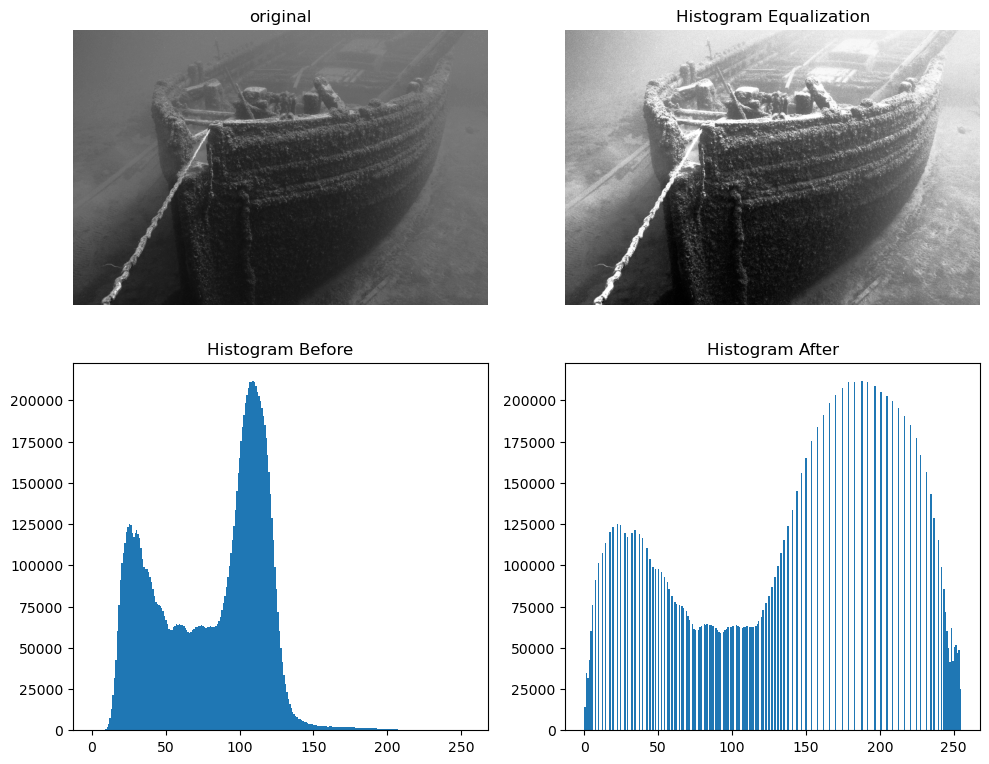

In [34]:
# 1- Histogram Equalization

import cv2
import matplotlib.pyplot as plt


img7 = cv2.imread("Used_Images/eq3.jpg", cv2.IMREAD_GRAYSCALE)

# Equalization
out2 = cv2.equalizeHist(img7)

fig, ax = plt.subplots(2, 2, figsize=(10, 8))


ax[0,0].imshow(img7, cmap='gray', vmin=0, vmax=255)
ax[0,0].set_title("original")
ax[0,0].axis("off")


ax[0,1].imshow(out2, cmap='gray', vmin=0, vmax=255)
ax[0,1].set_title("Histogram Equalization")
ax[0,1].axis("off")


ax[1,0].hist(img7.ravel(), bins=256, range=(0,255))
ax[1,0].set_title("Histogram Before")


ax[1,1].hist(out2.ravel(), bins=256, range=(0,255))
ax[1,1].set_title("Histogram After")

plt.tight_layout()
plt.show()

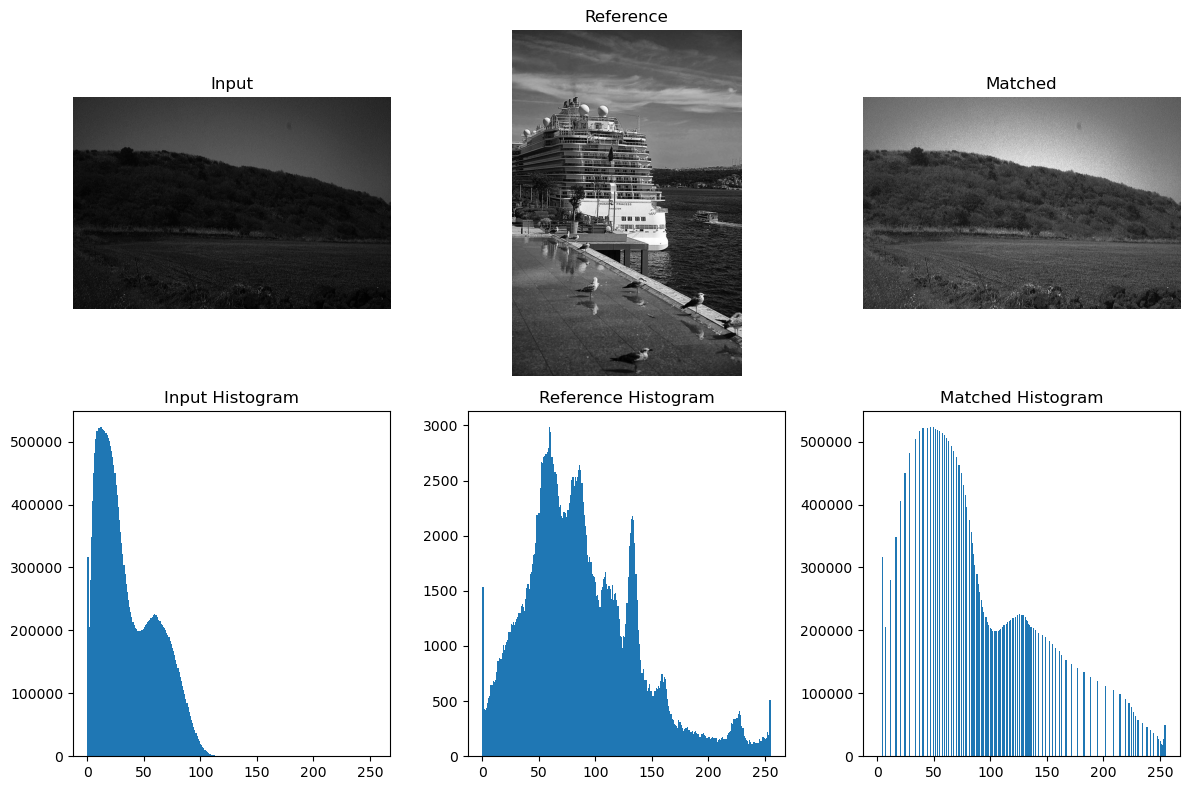

In [38]:
# 2- Histogram Matching

import cv2
import matplotlib.pyplot as plt
from skimage.exposure import match_histograms

img8 = cv2.imread("Used_Images/match1.jpg", cv2.IMREAD_GRAYSCALE)
reference = cv2.imread("Used_Images/source.jpg", cv2.IMREAD_GRAYSCALE) # Reference Image

matched = match_histograms(img8, reference)

fig, ax = plt.subplots(2, 3, figsize=(12, 8))

# تصاویر
ax[0,0].imshow(img8, cmap='gray', vmin=0, vmax=255)
ax[0,0].set_title("Input")
ax[0,0].axis("off")

ax[0,1].imshow(reference, cmap='gray', vmin=0, vmax=255)
ax[0,1].set_title("Reference")
ax[0,1].axis("off")

ax[0,2].imshow(matched, cmap='gray', vmin=0, vmax=255)
ax[0,2].set_title("Matched")
ax[0,2].axis("off")

# Histograms
ax[1,0].hist(img8.ravel(), bins=256, range=(0,255))
ax[1,0].set_title("Input Histogram")

ax[1,1].hist(reference.ravel(), bins=256, range=(0,255))
ax[1,1].set_title("Reference Histogram")

ax[1,2].hist(matched.ravel(), bins=256, range=(0,255))
ax[1,2].set_title("Matched Histogram")

plt.tight_layout()
plt.show()

Global Mean = 121.94
Global Std  = 78.54
Selected Pixels = 13624 / 262144
Percentage = 5.20%


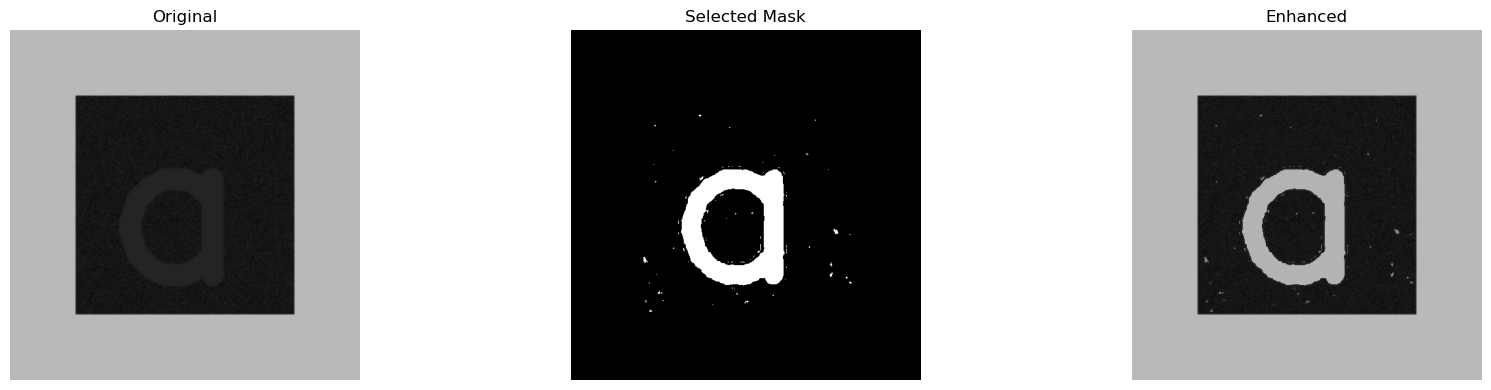

In [40]:
# 3- Local Histogram Statistic
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("Used_Images/xray1.jpg", cv2.IMREAD_GRAYSCALE)

img_f = img.astype(np.float32)

# Parameters (tuned)
ksize = 7

C = 5.0
k0 = 0.20
k1 = 0.50
k2 = 0.00
k3 = 0.06

# Global Mean & Standard Deviation
global_mean = np.mean(img_f)
global_std = np.std(img_f)

# Local Mean
local_mean = cv2.blur(img_f, (ksize, ksize))

# Local Standard Deviation
local_mean_sq = cv2.blur(img_f**2, (ksize, ksize))
local_var = local_mean_sq - local_mean**2
local_var = np.maximum(local_var, 0)
local_std = np.sqrt(local_var)

# Conditions
condition = (
    (local_mean >= k0 * global_mean) &
    (local_mean <= k1 * global_mean) &
    (local_std  >= k2 * global_std ) &
    (local_std  <= k3 * global_std )
)

selected_pixels = np.sum(condition)
total_pixels = condition.size

print(f"Global Mean = {global_mean:.2f}")
print(f"Global Std  = {global_std:.2f}")
print(f"Selected Pixels = {selected_pixels} / {total_pixels}")
print(f"Percentage = {100*selected_pixels/total_pixels:.2f}%")

if selected_pixels == 0:
    print("\nNo Pixel Satisfied The Conditions.")
    print("Try increasing k1 or k3 a little.")

# Enhancement
enhanced = img_f.copy()
enhanced[condition] = C * enhanced[condition]
enhanced = np.clip(enhanced, 0, 255).astype(np.uint8)


# Display
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

ax[0].imshow(img, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Original")
ax[0].axis("off")

ax[1].imshow(condition.astype(np.uint8) * 255, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Selected Mask")
ax[1].axis("off")

ax[2].imshow(enhanced, cmap="gray", vmin=0, vmax=255)
ax[2].set_title("Enhanced")
ax[2].axis("off")

plt.tight_layout()
plt.show()

## 9) Low Pass Filter - Box Filter و Gaussian Filter

- **1. Box Filter**
- **2. Gaussian Filter**

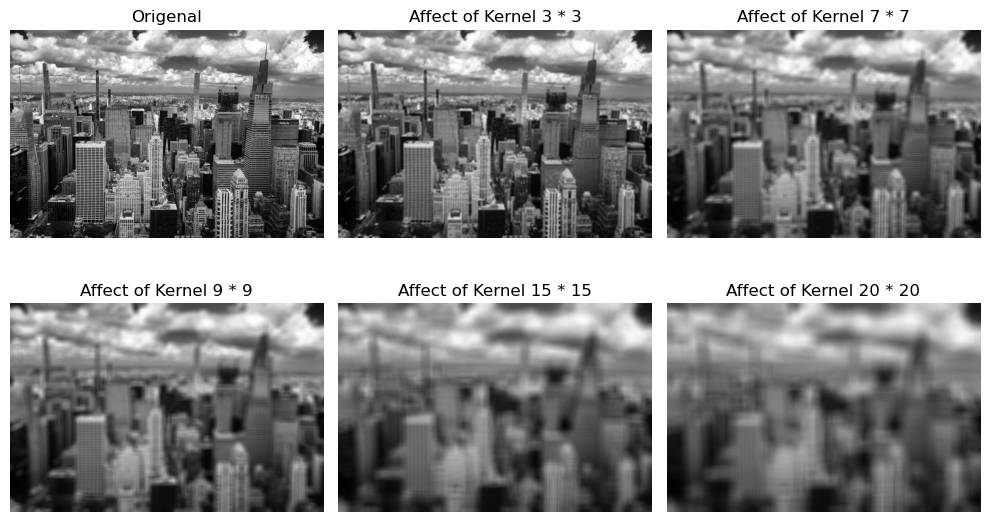

In [42]:
# 1- Box Filter

import cv2
import numpy as np

img9 = cv2.imread("Used_Images/city.jpg")
K = [3, 7, 9, 15, 20]

fig, ax = plt.subplots(2, 3, figsize=(10,6))
ax = ax.ravel()
ax[0].imshow(img9, cmap='gray', vmin=0, vmax=1)
ax[0].set_title("Origenal")
ax[0].axis('off')

for i, k in enumerate(K):
    
    kernel = np.ones((k, k), np.float32) / (k*k)
    out3 = cv2.filter2D(img9, -1, kernel)
    
    
    ax[i+1].imshow(out3, cmap='gray', vmin=0, vmax=1)
    ax[i+1].set_title(f"Affect of Kernel {k} * {k}")
    ax[i+1].axis('off')

plt.tight_layout()
plt.show()


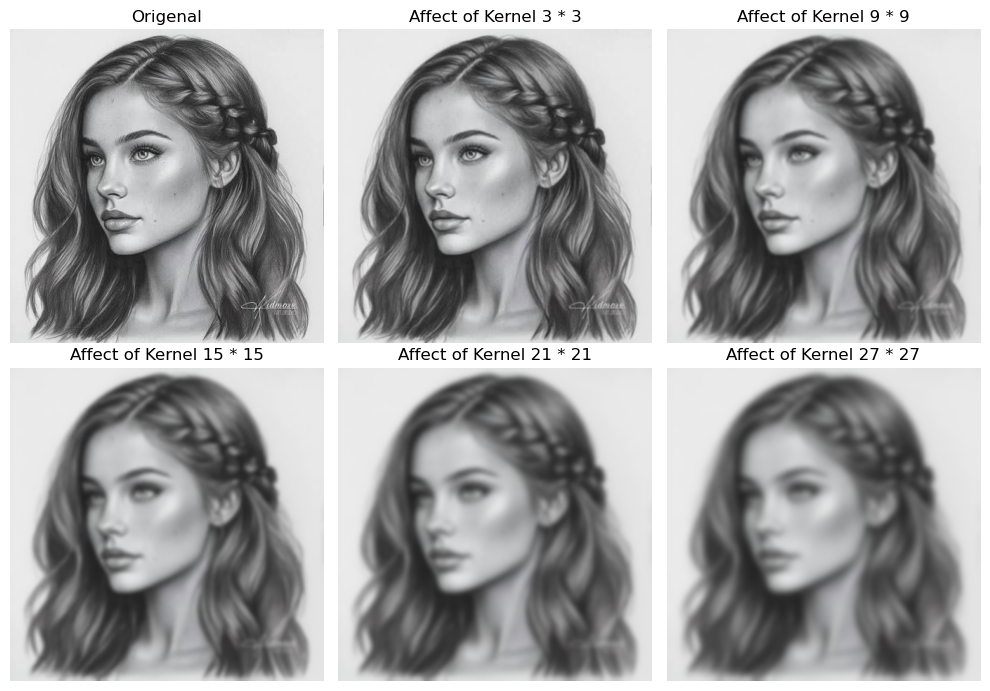

In [44]:
# 2- Gausian Kernel

import cv2

imeg = cv2.imread("Used_Images/box.jpg")           
K = [3, 9, 15, 21, 27]                             
sigma = 0                      # OpenCV count it

fig, ax = plt.subplots(2, 3, figsize=(10,7))
ax = ax.ravel()
ax[0].imshow(imeg, cmap='gray', vmin=0, vmax=1)
ax[0].set_title("Origenal")
ax[0].axis('off')

for i, k in enumerate(K):
    
    out4 = cv2.GaussianBlur(imeg, (k, k), sigma)
    
    
    ax[i+1].imshow(out4, cmap='gray', vmin=0, vmax=1)
    ax[i+1].set_title(f"Affect of Kernel {k} * {k}")
    ax[i+1].axis('off')

plt.tight_layout()
plt.show()

## 10) High Pass Filter - Sobel


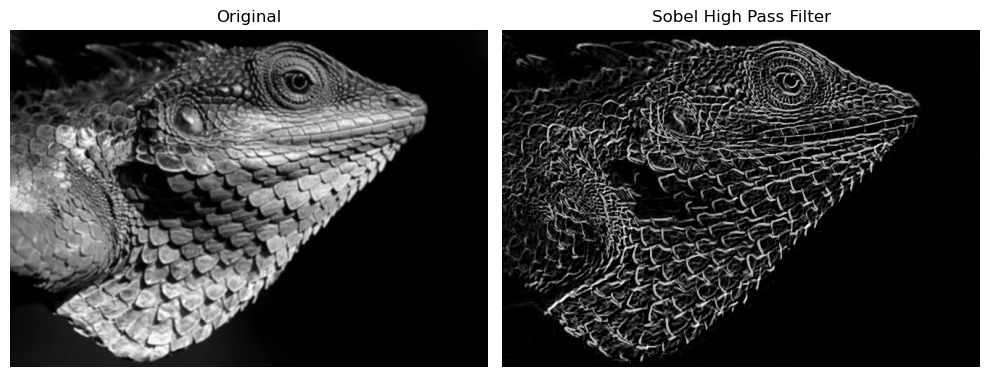

In [46]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imeg1 = cv2.imread("Used_Images/sob.jpg", cv2.IMREAD_GRAYSCALE)

sx = np.array([[-1, 0, 1],
               [-2, 0, 2],
               [-1, 0, 1]], dtype=np.float64)

sy = np.array([[-1, -2, -1],
               [ 0,  0,  0],
               [ 1,  2,  1]], dtype=np.float64)

gx = cv2.filter2D(imeg1, -1, sx)
gy = cv2.filter2D(imeg1, -1, sy)

mag = cv2.magnitude(gx.astype(np.float32),
                    gy.astype(np.float32))

mag = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
out5 = mag.astype(np.uint8)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(imeg1, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Original")
ax[0].axis("off")

ax[1].imshow(out5, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Sobel High Pass Filter")
ax[1].axis("off")

plt.tight_layout()
plt.show()